# 02 - Exploratory Data Analysis (EDA)
**Team 05 - The Budget Illusion | CS215: Data Analysis and Interpretation**

Data: `CleanedDataSet_final.csv` (1,317 films).
What we do: summary statistics -> histograms -> compare revenue across franchise / remake / release period -> count recurring lead stars and directors -> write observations.
Tools: pandas, matplotlib, scipy.stats.

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

plt.style.use("seaborn-v0_8-whitegrid")

## 1. Load the data

The cleaned file has the encoded variables (flags, genre dummies, `ROI`, `Movie_Scale`), but no `Lead Star`,
`Director` or `Release Period` text. We join those back from `DataSet.csv` using the movie title (every title
matches exactly once).

In [2]:
df = pd.read_csv("CleanedDataSet_final.csv").rename(
    columns={"Budget(INR)": "Budget", "Revenue(INR)": "Revenue"})

source = pd.read_csv("DataSet.csv")
df = df.merge(source[["Movie Name", "Release Period", "Lead Star", "Director"]],
              on="Movie Name", how="left")

print("rows:", len(df), " columns:", df.shape[1])
print("missing after join:", df[["Lead Star", "Director", "Release Period"]].isna().sum().to_dict())
df.head(3)

rows: 1317  columns: 32
missing after join: {'Lead Star': 0, 'Director': 0, 'Release Period': 0}


,row,Movie Name,Whether Remake,Whether Franchise,Holiday_Release,Genre_adult,Genre_animation,Genre_comedy,Genre_documentary,Genre_drama,Genre_fantasy,Genre_horror,Genre_love_story,Genre_masala,Genre_mythological,Genre_rom_com,Genre_suspense,Genre_thriller,Genre_action,Genre_unknown,New Actor,New Director,New Music Director,Budget,Revenue,Number of Screens,Revenue Per Screen,Movie_Scale,ROI,Release Period,Lead Star,Director
0,2,Qaidi Band,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,210000000,4500000,800,5.625000e+03,7.803,0.021429,Holiday,Aadar Jain,Habib Faisal
1,4,Shuttlecock Boys,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,5000000,170000,10,1.700000e+04,3.393,0.034000,Normal,Aakar Kaushik,Hemant Gaba
2,7,Ghajini,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,520000000,1945820000,1550,1.255368e+06,8.652,3.741962,Holiday,Aamir Khan,A.R. Murugadoss


In [3]:
# Data check: the cleaned file stores release period as a 0/1 flag.
# Does it agree with the text label in the source file?
print(pd.crosstab(df["Release Period"], df["Holiday_Release"], margins=True))
mismatch = (df["Holiday_Release"] != df["Release Period"].map({"Holiday": 1, "Normal": 0})).sum()
print(f"flag / label mismatches: {mismatch} rows ({mismatch / len(df):.1%})")

Holiday_Release    0    1   All
Release Period                 
Holiday          100  414   514
Normal           795    8   803
All              895  422  1317
flag / label mismatches: 108 rows (8.2%)


## 2. Summary statistics for Budget, Revenue and ROI

All three are right-skewed (a few blockbusters pull the mean far above the median), so the median is the more
honest summary of a typical film.

In [4]:
vars_of_interest = ["Budget", "Revenue", "ROI"]

summary = df[vars_of_interest].agg(["mean", "median", "std", "min", "max"]).T
summary["q1"] = df[vars_of_interest].quantile(0.25)
summary["q3"] = df[vars_of_interest].quantile(0.75)
summary["skew"] = df[vars_of_interest].skew()
summary = summary[["mean", "median", "std", "min", "max", "q1", "q3", "skew"]]

print("=== Summary statistics (n = %d) ===" % len(df))
print(summary.to_string(float_format=lambda v: f"{v:,.4f}"))

print("\n=== Same table in crore (1 crore = 10,000,000 INR); ROI is a ratio so it is left as is ===")
crore = summary.copy()
crore.loc[["Budget", "Revenue"], ["mean", "median", "std", "min", "max", "q1", "q3"]] /= 1e7
print(crore.to_string(float_format=lambda v: f"{v:,.3f}"))

=== Summary statistics (n = 1317) ===
                    mean          median              std            min                max              q1               q3   skew
Budget  180,212,376.6135 90,000,000.0000 246,324,939.9389 1,000,000.0000 2,100,000,000.0000 35,000,000.0000 220,000,000.0000 2.9949
Revenue 299,961,374.0607 41,200,000.0000 654,428,639.4733    14,000.0000 7,024,750,000.0000  3,600,000.0000 322,200,000.0000 4.7670
ROI               0.9926          0.5024           1.2266         0.0006             8.3867          0.1143           1.4315 2.0072

=== Same table in crore (1 crore = 10,000,000 INR); ROI is a ratio so it is left as is ===
          mean  median    std   min     max    q1     q3  skew
Budget  18.021   9.000 24.632 0.100 210.000 3.500 22.000 2.995
Revenue 29.996   4.120 65.443 0.001 702.475 0.360 32.220 4.767
ROI      0.993   0.502  1.227 0.001   8.387 0.114  1.432 2.007


In [5]:
print("Films that lost money (ROI < 1):          %.1f%%" % ((df["ROI"] < 1).mean() * 100))
print("Films with ROI below 0.5:                %.1f%%" % ((df["ROI"] < 0.5).mean() * 100))
print("Films grossing under 1 crore:            %.1f%%" % ((df["Revenue"] < 1e7).mean() * 100))
print("Films with budget above 10 crore:        %.1f%%" % ((df["Budget"] > 1e8).mean() * 100))

Films that lost money (ROI < 1):          65.1%
Films with ROI below 0.5:                49.8%
Films grossing under 1 crore:            34.2%
Films with budget above 10 crore:        45.0%


## 3. Histograms

First row: the variables as they are. Second row: the same data on a log10 scale, because on the raw scale nearly
every film is squeezed into the first bin.

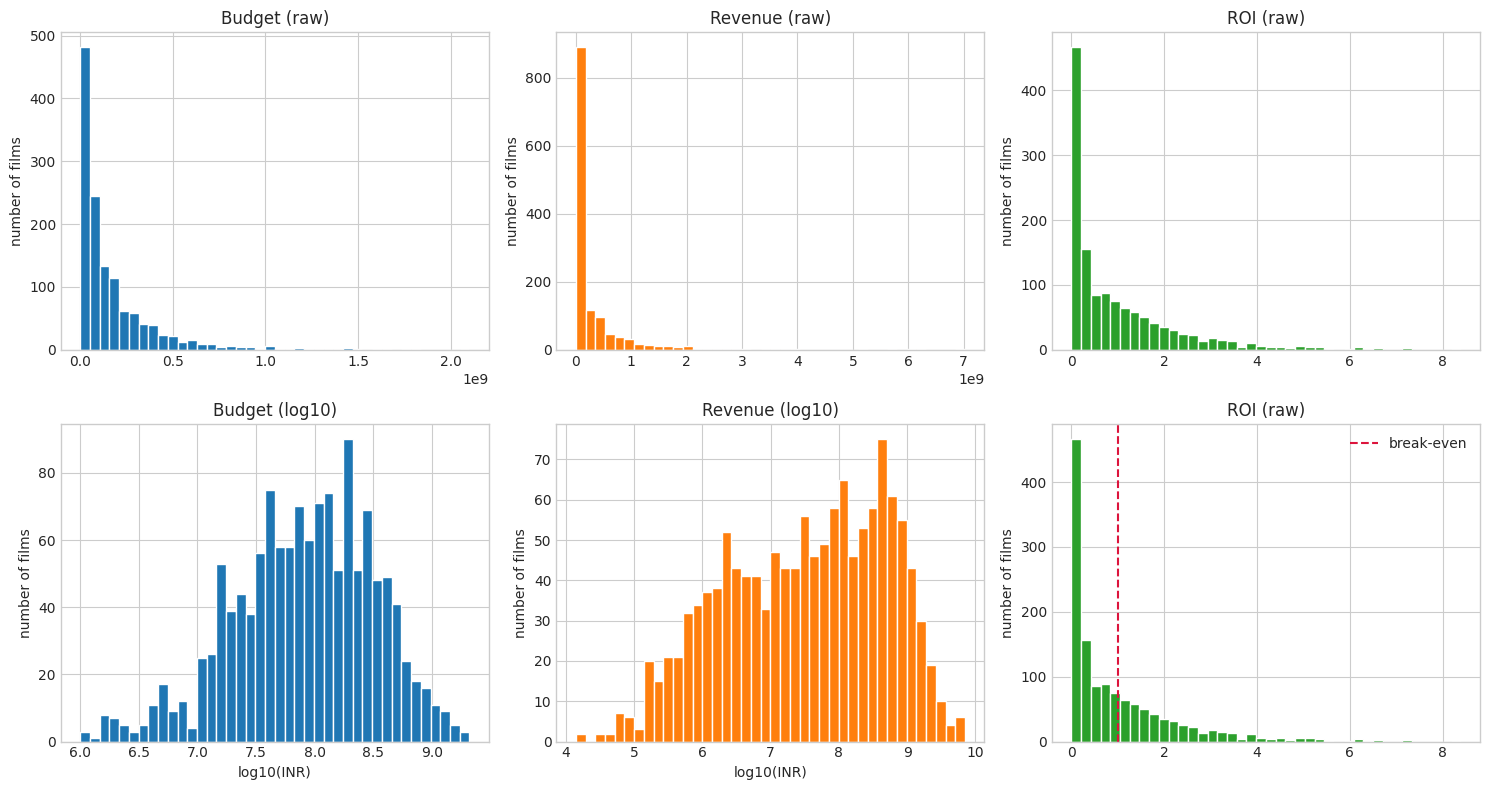

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for col, (variable, colour) in enumerate(zip(vars_of_interest, ["tab:blue", "tab:orange", "tab:green"])):
    ax = axes[0][col]
    ax.hist(df[variable], bins=40, color=colour, edgecolor="white")
    ax.set_title(f"{variable} (raw)")
    ax.set_ylabel("number of films")

    ax = axes[1][col]
    if variable == "ROI":
        ax.hist(df[variable], bins=40, color=colour, edgecolor="white")
        ax.axvline(1, color="crimson", linestyle="--", label="break-even")
        ax.legend()
        ax.set_title("ROI (raw)")
    else:
        logged = df[variable].apply(math.log10)
        ax.hist(logged, bins=40, color=colour, edgecolor="white")
        ax.set_title(f"{variable} (log10)")
        ax.set_xlabel("log10(INR)")
    ax.set_ylabel("number of films")

plt.tight_layout()
plt.show()

## 4. Franchise vs non-franchise films

`Whether Franchise` is 1 for franchise films and 0 for the rest.

In [7]:
def compare_groups(frame, column, label_1, label_0, value="Revenue"):
    # Print a small summary table for two groups and a t-test on the group means.
    table = frame.groupby(column)[value].agg(["count", "mean", "median", "std"])
    print(table.to_string(float_format=lambda v: f"{v:,.0f}"))

    group_1 = frame.loc[frame[column] == label_1, value]
    group_0 = frame.loc[frame[column] == label_0, value]
    t_stat, p_value = stats.ttest_ind(group_1, group_0, equal_var=False)
    print(f"\n{label_1} vs {label_0}: median {group_1.median():,.0f} vs {group_0.median():,.0f}"
          f"  ({group_1.median() / group_0.median():.1f}x),  Welch t-test p = {p_value:.2g}")

    # Budget and screens are shown too, so we can see how much of the gap is scale.
    print("\nMedian budget and screens by group:")
    print(frame.groupby(column)[["Budget", "Number of Screens", "ROI"]].median().to_string(float_format=lambda v: f"{v:,.2f}"))


print("=== Revenue by franchise status (INR) ===")
compare_groups(df, "Whether Franchise", 1, 0)

=== Revenue by franchise status (INR) ===
                   count        mean      median           std
Whether Franchise                                             
0                   1239 260,363,514  34,400,000   596,277,564
1                     78 928,958,151 577,717,500 1,084,978,915

1 vs 0: median 577,717,500 vs 34,400,000  (16.8x),  Welch t-test p = 6.9e-07

Median budget and screens by group:
                          Budget  Number of Screens  ROI
Whether Franchise                                       
0                  80,000,000.00             325.00 0.43
1                 290,000,000.00           1,500.00 1.93


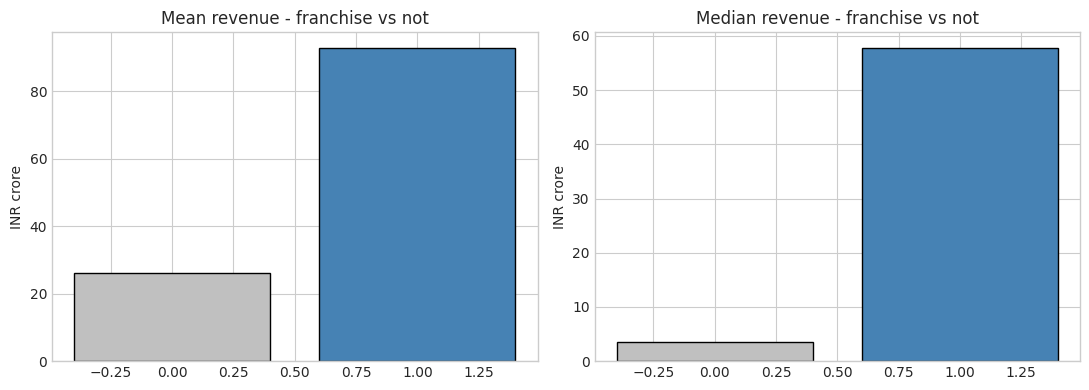

In [8]:
def bar_comparison(frame, column, labels, value="Revenue", title=""):
    # Two simple bars: mean revenue and median revenue for each group.
    means = frame.groupby(column)[value].mean() / 1e7
    medians = frame.groupby(column)[value].median() / 1e7

    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].bar(labels, means.loc[labels], color=["steelblue", "silver"], edgecolor="black")
    axes[0].set_ylabel("INR crore")
    axes[0].set_title("Mean revenue")
    axes[1].bar(labels, medians.loc[labels], color=["steelblue", "silver"], edgecolor="black")
    axes[1].set_ylabel("INR crore")
    axes[1].set_title("Median revenue")
    for ax in axes:
        ax.set_title(ax.get_title() + " - " + title)
    plt.tight_layout()
    plt.show()


bar_comparison(df, "Whether Franchise", [1, 0], title="franchise vs not")

## 5. Remake vs non-remake films

In [9]:
print("=== Revenue by remake status (INR) ===")
compare_groups(df, "Whether Remake", 1, 0)

=== Revenue by remake status (INR) ===
                count        mean      median         std
Whether Remake                                           
0                1191 268,651,664  30,900,000 646,327,139
1                 126 595,912,685 359,099,375 659,088,287

1 vs 0: median 359,099,375 vs 30,900,000  (11.6x),  Welch t-test p = 3.8e-07

Median budget and screens by group:
                       Budget  Number of Screens  ROI
Whether Remake                                       
0               80,000,000.00             325.00 0.39
1              240,000,000.00           1,075.00 1.39


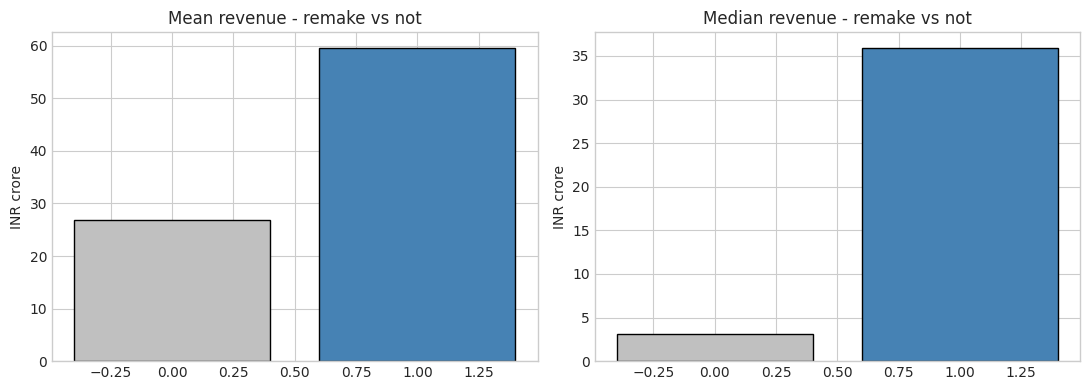

In [10]:
bar_comparison(df, "Whether Remake", [1, 0], title="remake vs not")

## 6. Revenue across release periods

In [11]:
print("=== Revenue by release period (INR) ===")
compare_groups(df, "Release Period", "Holiday", "Normal")

print("\n=== Same comparison using the 0/1 flag stored in the cleaned file (robustness check) ===")
compare_groups(df, "Holiday_Release", 1, 0)

=== Revenue by release period (INR) ===
                count        mean     median         std
Release Period                                          
Holiday           514 459,119,332 78,800,000 927,031,026
Normal            803 198,084,425 32,700,000 355,562,334

Holiday vs Normal: median 78,800,000 vs 32,700,000  (2.4x),  Welch t-test p = 1.8e-09

Median budget and screens by group:
                       Budget  Number of Screens  ROI
Release Period                                       
Holiday        110,000,000.00             500.00 0.71
Normal          77,500,000.00             325.00 0.40

=== Same comparison using the 0/1 flag stored in the cleaned file (robustness check) ===
                 count        mean     median         std
Holiday_Release                                          
0                  895 208,599,914 34,400,000 389,838,751
1                  422 493,725,607 88,184,750 980,126,808

1 vs 0: median 88,184,750 vs 34,400,000  (2.6x),  Welch t-test p = 1.

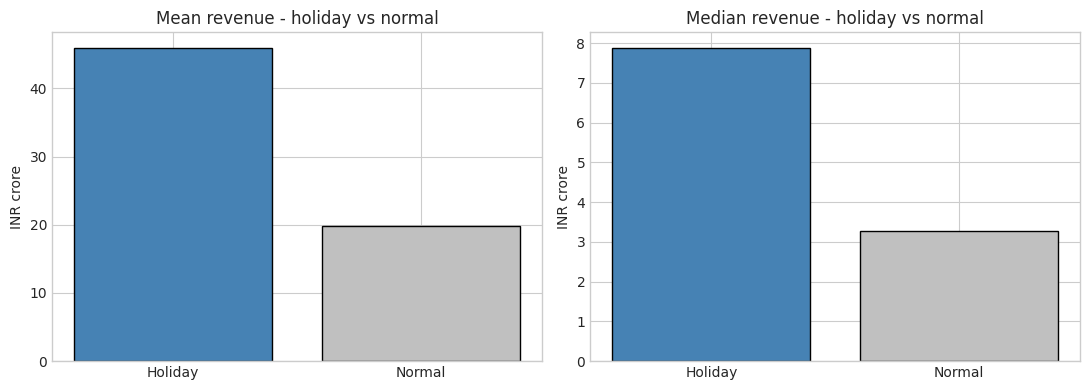

In [12]:
bar_comparison(df, "Release Period", ["Holiday", "Normal"], title="holiday vs normal")

## 7. Recurring lead stars and directors

In [13]:
star_counts = df["Lead Star"].value_counts()
director_counts = df["Director"].value_counts()

print("=== Top 15 lead stars by number of films ===")
print(star_counts.head(15).to_string())
print("\ndistinct lead stars:", df["Lead Star"].nunique())
print("share of films with a top-10 star: %.1f%%" % (star_counts.head(10).sum() / len(df) * 100))
print("films whose lead star appears only once: %d (%.1f%%)" % ((star_counts == 1).sum(), (star_counts == 1).sum() / len(df) * 100))

print("\n=== Top 15 directors by number of films ===")
print(director_counts.head(15).to_string())
print("\ndistinct directors:", df["Director"].nunique())
print("share of films with a top-10 director: %.1f%%" % (director_counts.head(10).sum() / len(df) * 100))
print("films whose director appears only once: %d (%.1f%%)" % ((director_counts == 1).sum(), (director_counts == 1).sum() / len(df) * 100))

=== Top 15 lead stars by number of films ===
Lead Star
Akshay Kumar        48
Ajay Devgn          34
Emraan Hashmi       27
Salman Khan         26
Amitabh Bachchan    19
Saif Ali Khan       19
Sanjay Dutt         18
Shahid Kapoor       18
John Abraham        16
Ranbir Kapoor       16
Shahrukh Khan       16
Jimmy Shergill      15
Sunny Deol          15
Naseeruddin Shah    13
Tusshar Kapoor      13

distinct lead stars: 501
share of films with a top-10 star: 18.3%
films whose lead star appears only once: 330 (25.1%)

=== Top 15 directors by number of films ===
Director
Ram Gopal Verma      18
Vikram Bhatt         16
Priyadarshan         16
Rohit Shetty         11
Mohit Suri           11
Anurag Kashyap       10
Anees Bazmee          9
Madhur Bhandarkar     9
Anant Mahadevan       8
David Dhawan          8
Vishal Bhardwaj       7
Abbas - Mustan        7
Nagesh Kukunoor       7
Imtiaz Ali            7
Indra Kumar           6

distinct directors: 767
share of films with a top-10 director: 8.

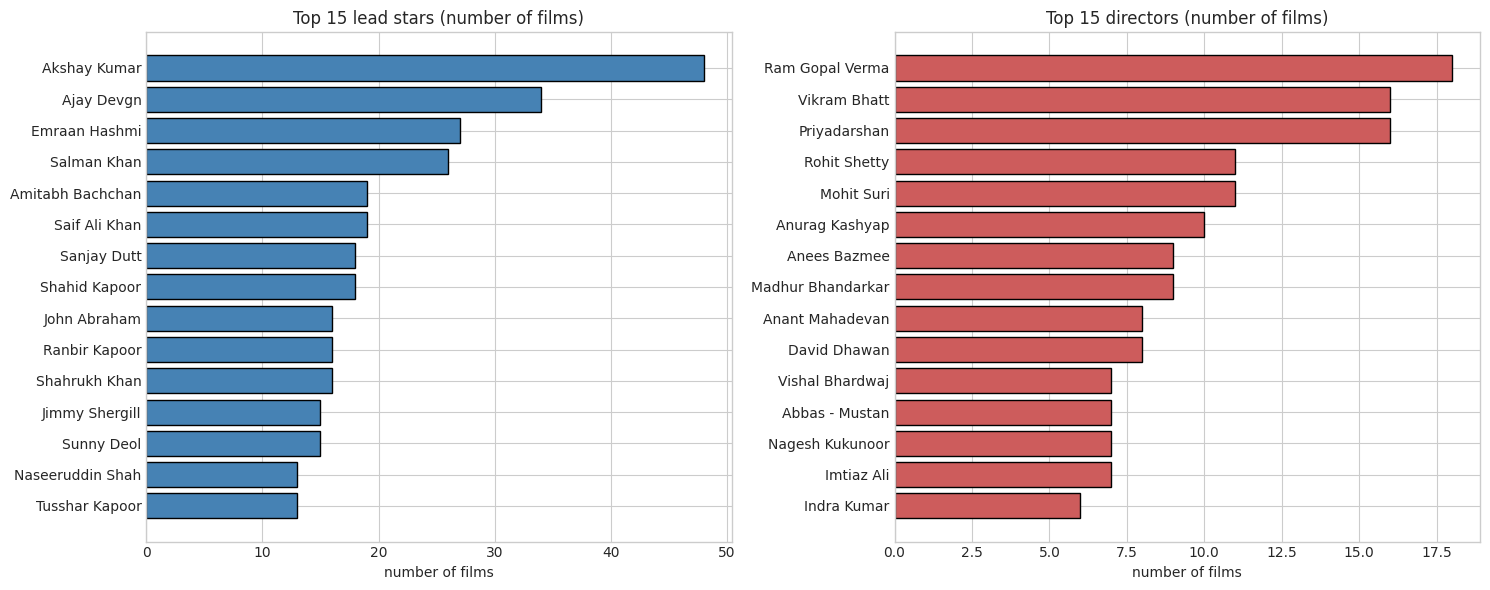

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top_stars = star_counts.head(15).iloc[::-1]
axes[0].barh(top_stars.index, top_stars.values, color="steelblue", edgecolor="black")
axes[0].set_title("Top 15 lead stars (number of films)")
axes[0].set_xlabel("number of films")

top_directors = director_counts.head(15).iloc[::-1]
axes[1].barh(top_directors.index, top_directors.values, color="indianred", edgecolor="black")
axes[1].set_title("Top 15 directors (number of films)")
axes[1].set_xlabel("number of films")

plt.tight_layout()
plt.show()

In [15]:
# Do the busiest names also earn more?
top_stars = star_counts.head(10).index
top_directors = director_counts.head(10).index

for label, names in [("top-10 lead stars", top_stars), ("top-10 directors", top_directors)]:
    with_name = df.loc[df["Lead Star"].isin(names) if "star" in label else df["Director"].isin(names), "Revenue"]
    without_name = df.loc[~df["Lead Star"].isin(names) if "star" in label else ~df["Director"].isin(names), "Revenue"]
    print(f"{label}: median {with_name.median() / 1e7:,.2f} crore (n={len(with_name)}) vs "
          f"{without_name.median() / 1e7:,.2f} crore (n={len(without_name)})")

top-10 lead stars: median 46.29 crore (n=241) vs 1.92 crore (n=1076)
top-10 directors: median 21.43 crore (n=116) vs 3.24 crore (n=1201)


## 8. Observations

**1. The typical film is far weaker than the average suggests.**
Mean budget is Rs 18.0 crore but the median is Rs 9.0 crore; mean revenue is Rs 30.0 crore but the median is only
Rs 4.1 crore (revenue skew = 4.77). **65.1% of the films lost money** (ROI below 1) and 34.2% grossed under
Rs 1 crore, so a handful of blockbusters are carrying the averages.

**2. Franchise and remake films earn much more, but they are also much bigger films.**
Franchise films (n = 78) have a median revenue of Rs 57.8 crore against Rs 3.4 crore for the rest (t-test p = 6.9e-07),
and remakes (n = 126) Rs 35.9 crore against Rs 3.1 crore (p = 3.8e-07). Part of that gap is scale: the median
franchise budget is Rs 29 crore and the median remake budget Rs 24 crore, versus Rs 8 crore for everything else.
Their ROI is higher too (franchise median 1.93 vs 0.43, remake 1.39 vs 0.39), so the gap is not purely mechanical,
but absolute revenue differences between these groups and the rest are inflated by size.

**3. Holiday releases earn more without being dramatically bigger films.**
Holiday films (n = 514) have a median revenue of Rs 7.9 crore versus Rs 3.3 crore for normal releases
(p = 1.9e-09). Their median budget is Rs 11.0 crore against Rs 7.8 crore and their median ROI is 0.71 against 0.40,
so the revenue gap (2.4x) is larger than the budget gap (1.4x) - release timing looks like it pays beyond scale.
This is still an association, not a cause.

**4. The money is concentrated in a small set of recurring names.**
The 1,317 films cover 501 different lead stars and 767 different directors. The top 10 stars appear on only 18.3%
of the films and the top 10 directors on 8.8%, yet films with a top-10 star earn a median of Rs 46.3 crore versus
Rs 1.9 crore for the rest, and films with a top-10 director Rs 21.4 crore versus Rs 3.2 crore. Akshay Kumar
(48 films), Ajay Devgn (34) and Emraan Hashmi (27) lead the star counts; Ram Gopal Verma (18), Vikram Bhatt (16)
and Priyadarshan (16) lead the director counts. These names are also given bigger budgets and screens, so
recurrence marks the successful films rather than explaining them.

**One caveat for the next stage.** The release-period flag inside `CleanedDataSet_final.csv` disagrees with the
source label on 108 of 1,317 rows (8.2%), and the dataset has no release year, so the rupee amounts are nominal and
not inflation adjusted.